<img src="https://www.collinsdictionary.com/images/full/xray_560923156_1000.jpg" width="620" height="360" align="center"/>

In [7]:

import kagglehub
paultimothymooney_chest_xray_pneumonia_path = kagglehub.dataset_download('paultimothymooney/chest-xray-pneumonia')
tolgadincer_labeled_chest_xray_images_path = kagglehub.dataset_download('tolgadincer/labeled-chest-xray-images')

print('Data source import complete.')


Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Using Colab cache for faster access to the 'labeled-chest-xray-images' dataset.
Data source import complete.


<br>
<h1 style = "font-size:30px; font-weight : bold; color : blue; text-align: center; border-radius: 10px 15px;">Chest X-Ray (Pneumonia): Image Classification w/Convolutional Neural Networks and Transfer Learning</h1>
<br>

---

# Overview

The goal of this notebook is to use Convolutional Neural Networks on Chest X-Ray images to determine which samples are from patients with Pneumonia. In this dataset (version 3), there is one folder representing the train set and another one for the test set. The train folder is later split in the notebook into train/validation sets.

I use three different approaches for image classification: 1) A simple CNN, 2) Transfer Learning, using a pretrained model with frozen layers as the base for feature extraction and 3) Fine Tuning, unfreezing the last layers of the pretrained model.

Note: I’m using the third version of the Chest X-Ray dataset [(link)](https://www.kaggle.com/tolgadincer/labeled-chest-xray-images)

# <a id='0'>Content</a>
​
- <a href='#1'>Dataset Information</a>  
- <a href='#2'>Importing Packages and Dataset</a>  
- <a href='#3'>Exploring the Data</a>  
- <a href='#4'>Preparing the Data</a>
- <a href='#5'>Custom Model</a>
- <a href='#6'>Transfer Learning</a>
- <a href='#7'>Fine Tuning</a>
- <a href='#8'>Performance Metrics</a>
- <a href='#9'>References</a>

# <a id="1">Dataset Information</a>

This dataset contains 5,856 validated Chest X-Ray images. The images are split into a training set and a testing set of independent patients. Images are labeled as (disease:NORMAL/BACTERIA/VIRUS)-(randomized patient ID)-(image number of a patient).

Chest X-ray images (anterior-posterior) were selected from retrospective cohorts of pediatric patients of one to five years old from Guangzhou Women and Children’s Medical Center, Guangzhou. All chest X-ray imaging was performed as part of patients’ routine clinical care.

For the analysis of chest x-ray images, all chest radiographs were initially screened for quality control by removing all low quality or unreadable scans. The diagnoses for the images were then graded by two expert physicians before being cleared for training the AI system. In order to account for any grading errors, the evaluation set was also checked by a third expert.

## <center> If you find this notebook useful, support with an upvote! <center>

# <a id="2">Importing Packages and Dataset</a>

In [8]:
import pandas as pd
import matplotlib as mat
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
%matplotlib inline

pd.options.display.max_colwidth = 100

import random
import os

from numpy.random import seed
seed(42)

random.seed(42)
os.environ['PYTHONHASHSEED'] = str(42)
os.environ['TF_DETERMINISTIC_OPS'] = '1'

from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import accuracy_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import callbacks
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import glob
import cv2

from tensorflow.random import set_seed
set_seed(42)

import warnings
warnings.filterwarnings('ignore')

In [9]:
IMG_SIZE = 224
BATCH = 32
SEED = 42

In [10]:
#main_path = "../input/chest-xray-pneumonia/chest_xray/"
main_path = tolgadincer_labeled_chest_xray_images_path + "/chest_xray"


train_path = os.path.join(main_path,"train")
test_path=os.path.join(main_path,"test")

train_normal = glob.glob(train_path+"/NORMAL/*.jpeg")
train_pneumonia = glob.glob(train_path+"/PNEUMONIA/*.jpeg")

test_normal = glob.glob(test_path+"/NORMAL/*.jpeg")
test_pneumonia = glob.glob(test_path+"/PNEUMONIA/*.jpeg")

In [11]:
train_list = [x for x in train_normal]
train_list.extend([x for x in train_pneumonia])

df_train = pd.DataFrame(np.concatenate([['Normal']*len(train_normal) , ['Pneumonia']*len(train_pneumonia)]), columns = ['class'])
df_train['image'] = [x for x in train_list]

test_list = [x for x in test_normal]
test_list.extend([x for x in test_pneumonia])

df_test = pd.DataFrame(np.concatenate([['Normal']*len(test_normal) , ['Pneumonia']*len(test_pneumonia)]), columns = ['class'])
df_test['image'] = [x for x in test_list]

In [12]:
df_train

,class,image
0,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/train/NORMAL/NORMAL-705219-0001.jpeg
1,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/train/NORMAL/NORMAL-9031828-0001.jpeg
2,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/train/NORMAL/NORMAL-9211217-0001.jpeg
3,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/train/NORMAL/NORMAL-8050432-0001.jpeg
4,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/train/NORMAL/NORMAL-6897353-0001.jpeg
...,...,...
5227,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/BACTERIA-3852742-0001.jpeg
5228,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/BACTERIA-4313165-0003.jpeg
5229,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/BACTERIA-6518955-0001.jpeg
5230,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/BACTERIA-3076396-0001.jpeg


In [13]:
df_test

,class,image
0,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/test/NORMAL/NORMAL-6293151-0001.jpeg
1,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/test/NORMAL/NORMAL-4315572-0001.jpeg
2,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/test/NORMAL/NORMAL-5893138-0001.jpeg
3,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/test/NORMAL/NORMAL-7225301-0001.jpeg
4,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/test/NORMAL/NORMAL-1627110-0001.jpeg
...,...,...
619,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/test/PNEUMONIA/BACTERIA-5754167-0001.jpeg
620,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/test/PNEUMONIA/BACTERIA-8983865-0002.jpeg
621,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/test/PNEUMONIA/VIRUS-6831597-0001.jpeg
622,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/test/PNEUMONIA/VIRUS-2040583-0002.jpeg


# <a id="3">Exploring the Data</a>

Let's check the target distribution on each set

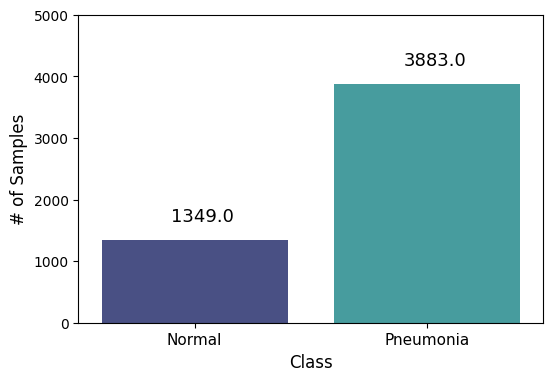

In [14]:
plt.figure(figsize=(6,4))

ax = sns.countplot(x='class', data=df_train, palette="mako")

plt.xlabel("Class", fontsize= 12)
plt.ylabel("# of Samples", fontsize= 12)
plt.ylim(0,5000)
plt.xticks([0,1], ['Normal', 'Pneumonia'], fontsize = 11)

for p in ax.patches:
    ax.annotate((p.get_height()), (p.get_x()+0.30, p.get_height()+300), fontsize = 13)

plt.show()

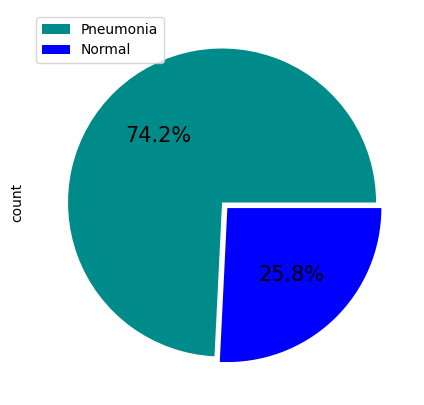

In [15]:
plt.figure(figsize=(7,5))

df_train['class'].value_counts().plot(kind='pie',labels = ['',''], autopct='%1.1f%%', colors = ['darkcyan','blue'], explode = [0,0.05], textprops = {"fontsize":15})

plt.legend(labels=['Pneumonia', 'Normal'])
plt.show()

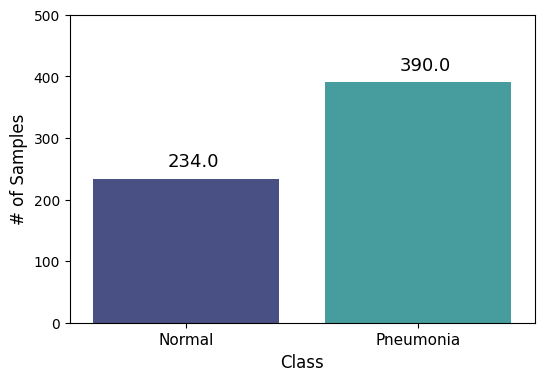

In [16]:
plt.figure(figsize=(6,4))

ax = sns.countplot(x='class', data=df_test, palette="mako")

plt.xlabel("Class", fontsize= 12)
plt.ylabel("# of Samples", fontsize= 12)
plt.ylim(0,500)
plt.xticks([0,1], ['Normal', 'Pneumonia'], fontsize = 11)

for p in ax.patches:
    ax.annotate((p.get_height()), (p.get_x()+0.32, p.get_height()+20), fontsize = 13)

plt.show()

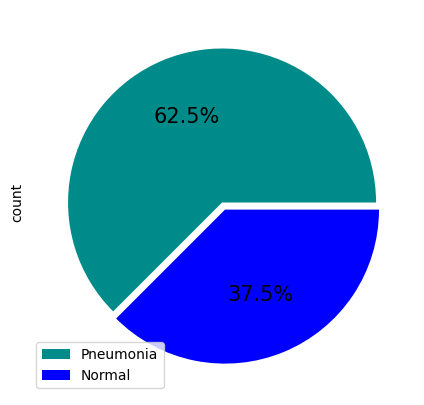

In [17]:
plt.figure(figsize=(7,5))

df_test['class'].value_counts().plot(kind='pie',labels = ['',''], autopct='%1.1f%%', colors = ['darkcyan','blue'], explode = [0,0.05], textprops = {"fontsize":15})

plt.legend(labels=['Pneumonia', 'Normal'])
plt.show()

The distributions from these datasets are a little different from each other. Both are slightly imbalanced, having more samples from the positive class (Pneumonia), with the training set being a little more imbalanced.

Before we move on to the next section, we will take a look at a few examples from each dataset.

Train Set - Normal


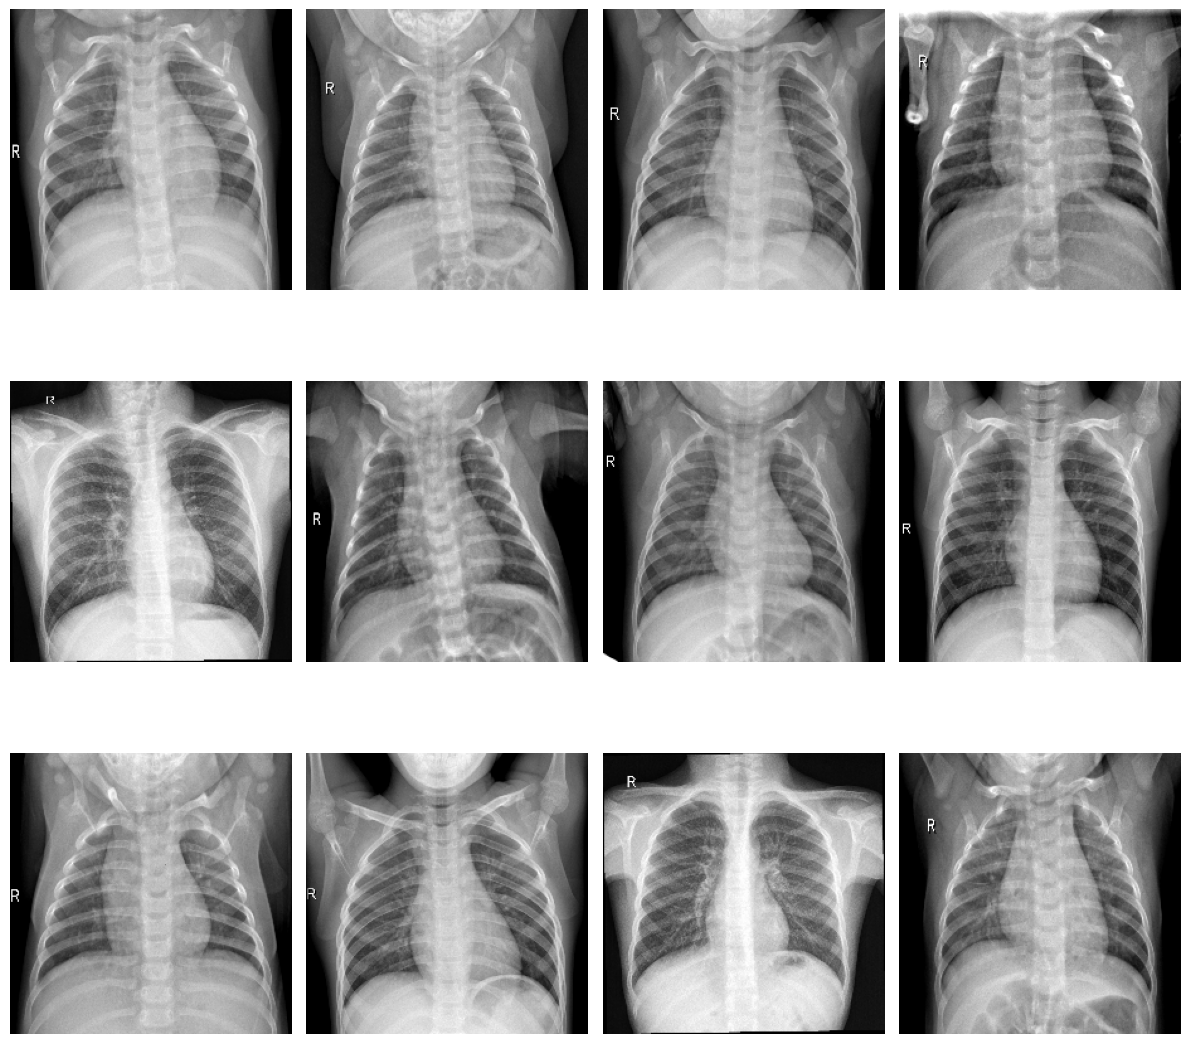

In [18]:
print('Train Set - Normal')

plt.figure(figsize=(12,12))

for i in range(0, 12):
    plt.subplot(3,4,i + 1)
    img = cv2.imread(train_normal[i])
    img = cv2.resize(img, (IMG_SIZE,IMG_SIZE))
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()

plt.show()

Train Set - Pneumonia


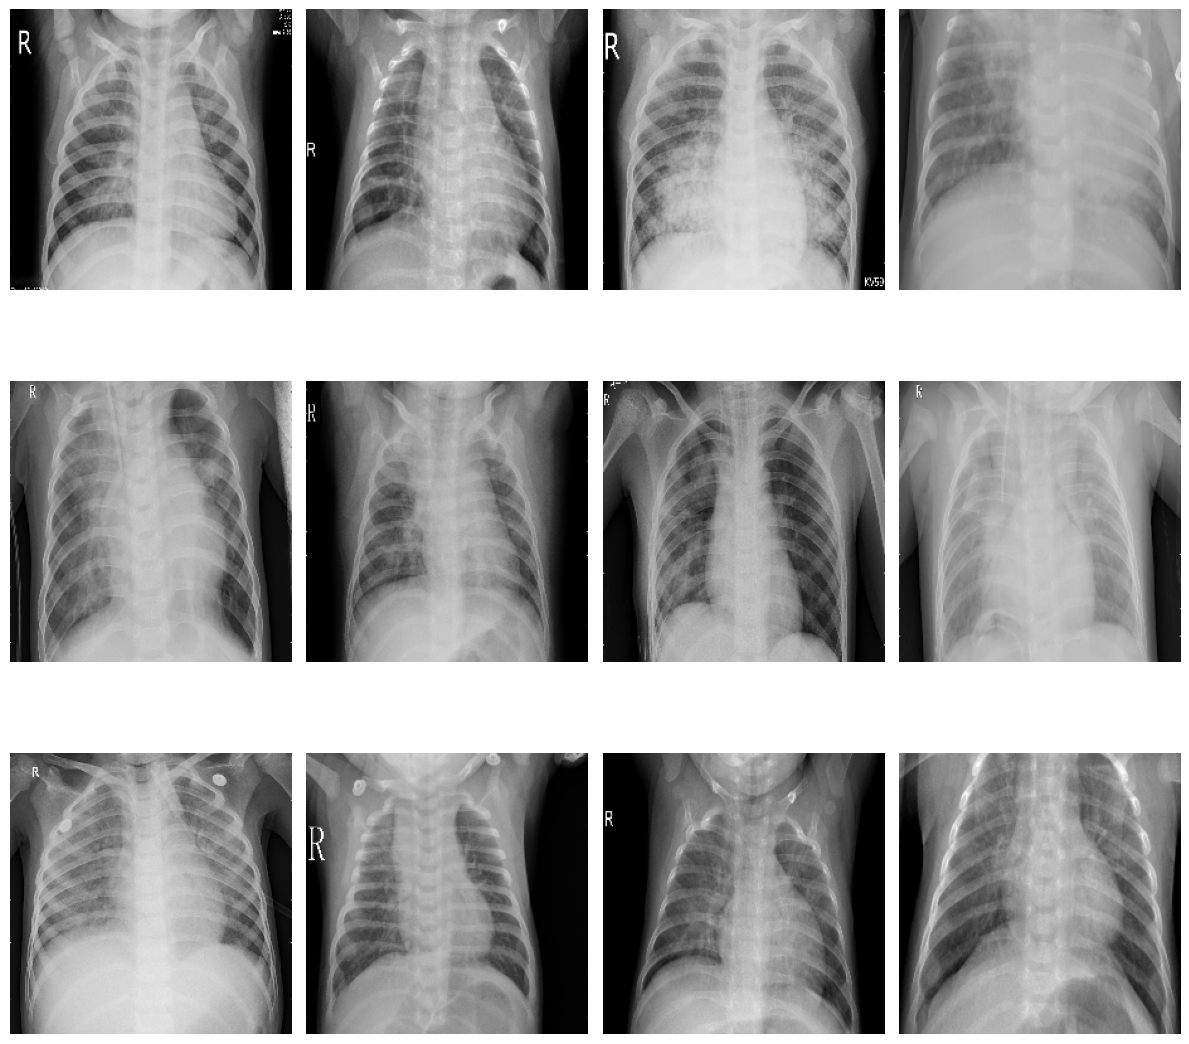

In [19]:
print('Train Set - Pneumonia')

plt.figure(figsize=(12,12))

for i in range(0, 12):
    plt.subplot(3,4,i + 1)
    img = cv2.imread(train_pneumonia[i])
    img = cv2.resize(img, (IMG_SIZE,IMG_SIZE))
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()

plt.show()

Test Set - Normal


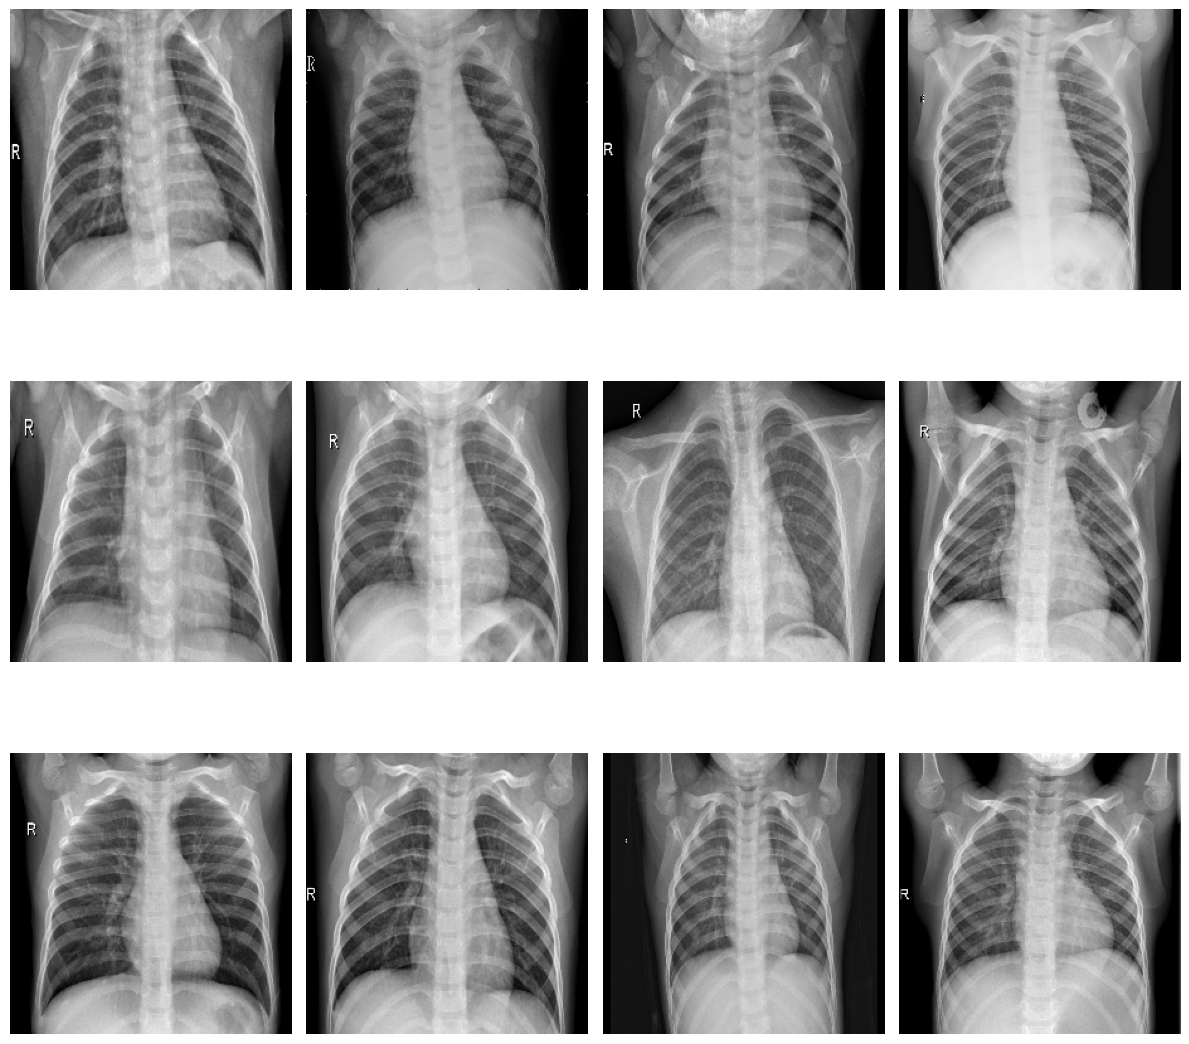

In [20]:
print('Test Set - Normal')

plt.figure(figsize=(12,12))

for i in range(0, 12):
    plt.subplot(3,4,i + 1)
    img = cv2.imread(test_normal[i])
    img = cv2.resize(img, (IMG_SIZE,IMG_SIZE))
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()

plt.show()

Test Set - Pneumonia


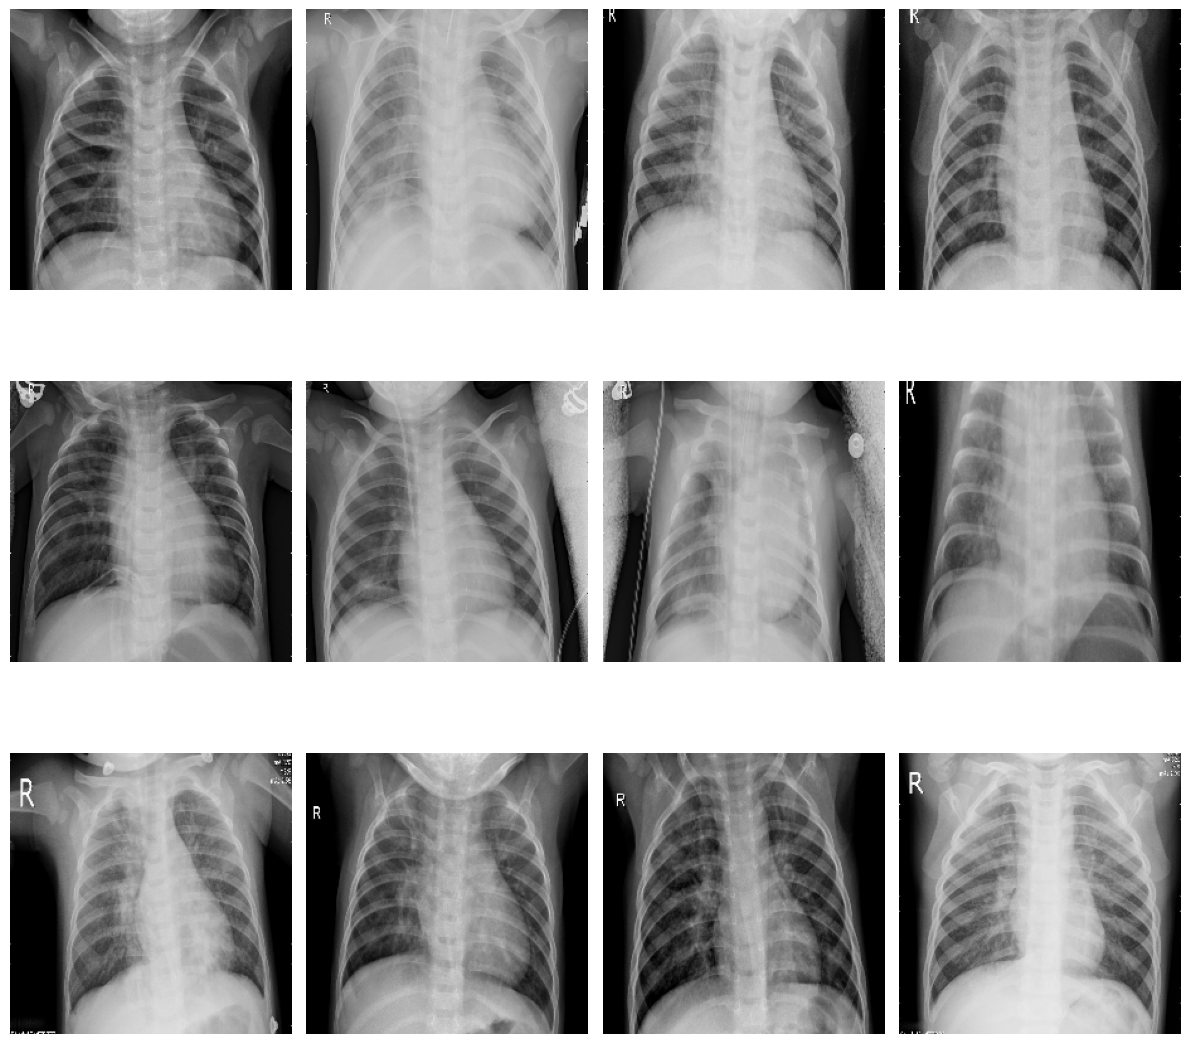

In [21]:
print('Test Set - Pneumonia')

plt.figure(figsize=(12,12))

for i in range(0, 12):
    plt.subplot(3,4,i + 1)
    img = cv2.imread(test_pneumonia[i])
    img = cv2.resize(img, (IMG_SIZE,IMG_SIZE))
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()

plt.show()

# <a id="4">Preparing the Data</a>

First, we need to create a validation set. To do that, we apply a simple stratified split on the original train dataset, using 80% for actual training and 20% for validation purposes.

In [22]:
train_df, val_df = train_test_split(df_train, test_size = 0.20, random_state = SEED, stratify = df_train['class'])

In [23]:
train_df

,class,image
3566,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/VIRUS-6559742-0002.jpeg
2866,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/BACTERIA-4609274-0001.jpeg
2681,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/VIRUS-1149864-0002.jpeg
1199,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/train/NORMAL/NORMAL-6315622-0002.jpeg
4619,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/BACTERIA-1753514-0002.jpeg
...,...,...
3476,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/VIRUS-3408906-0008.jpeg
678,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/train/NORMAL/NORMAL-4688588-0001.jpeg
1560,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/BACTERIA-8467199-0001.jpeg
2769,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/BACTERIA-6909155-0001.jpeg


In [24]:
val_df

,class,image
2945,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/BACTERIA-2474652-0008.jpeg
4878,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/BACTERIA-2739133-0001.jpeg
3177,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/BACTERIA-4133607-0005.jpeg
972,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/train/NORMAL/NORMAL-3476904-0001.jpeg
3059,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/VIRUS-8446214-0003.jpeg
...,...,...
253,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/train/NORMAL/NORMAL-9862823-0002.jpeg
4315,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/BACTERIA-1083680-0014.jpeg
687,Normal,/kaggle/input/labeled-chest-xray-images/chest_xray/train/NORMAL/NORMAL-8991560-0001.jpeg
3417,Pneumonia,/kaggle/input/labeled-chest-xray-images/chest_xray/train/PNEUMONIA/BACTERIA-7942103-0006.jpeg


Now, we’re going to load the images from the folders and prepare them to feed our models.

We begin by defining the data generators. With Keras Image Data Generator, we can rescale the pixel values and apply random transformation techniques for data augmentation on the fly. We define two different generators. The val_datagen is used to simply rescale the validation and test sets. The train_datagen includes some transformations to augment the train set.

We apply those generators on each dataset using the flow_from_dataframe method. Apart from the transformations defined in each generator, the images are also resized based on the target_size set.

In [25]:
# https://vijayabhaskar96.medium.com/tutorial-on-keras-flow-from-dataframe-1fd4493d237c

train_datagen = ImageDataGenerator(rescale=1/255.,
                                  zoom_range = 0.1,
                                  #rotation_range = 0.1,
                                  width_shift_range = 0.1,
                                  height_shift_range = 0.1)

val_datagen = ImageDataGenerator(rescale=1/255.)

ds_train = train_datagen.flow_from_dataframe(train_df,
                                             #directory=train_path, #dataframe contains the full paths
                                             x_col = 'image',
                                             y_col = 'class',
                                             target_size = (IMG_SIZE, IMG_SIZE),
                                             class_mode = 'binary',
                                             batch_size = BATCH,
                                             seed = SEED)

ds_val = val_datagen.flow_from_dataframe(val_df,
                                            #directory=train_path,
                                            x_col = 'image',
                                            y_col = 'class',
                                            target_size = (IMG_SIZE, IMG_SIZE),
                                            class_mode = 'binary',
                                            batch_size = BATCH,
                                            seed = SEED)

ds_test = val_datagen.flow_from_dataframe(df_test,
                                            #directory=test_path,
                                            x_col = 'image',
                                            y_col = 'class',
                                            target_size = (IMG_SIZE, IMG_SIZE),
                                            class_mode = 'binary',
                                            batch_size = 1,
                                            shuffle = False)

Found 4185 validated image filenames belonging to 2 classes.
Found 1047 validated image filenames belonging to 2 classes.
Found 624 validated image filenames belonging to 2 classes.


Now, we are ready for the next stage: creating and training the image classification models.

# <a id="5">Custom CNN</a>

In [26]:
#Setting callbakcs

early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta=1e-7,
    restore_best_weights=True,
)

plateau = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor = 0.2,
    patience = 2,
    min_delt = 1e-7,
    cooldown = 0,
    verbose = 1
)

Let's define our first model 'from scratch' and see how it performs.

In [21]:
def get_model():

    #Input shape = [width, height, color channels]
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # Block One
    x = layers.Conv2D(filters=16, kernel_size=3, padding='valid')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPool2D()(x)
    x = layers.Dropout(0.2)(x)

    # Block Two
    x = layers.Conv2D(filters=32, kernel_size=3, padding='valid')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPool2D()(x)
    x = layers.Dropout(0.2)(x)

    # Block Three
    x = layers.Conv2D(filters=64, kernel_size=3, padding='valid')(x)
    x = layers.Conv2D(filters=64, kernel_size=3, padding='valid')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPool2D()(x)
    x = layers.Dropout(0.4)(x)

    # Head
    #x = layers.BatchNormalization()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.5)(x)

    #Final Layer (Output)
    output = layers.Dense(1, activation='sigmoid')(x)

    model = keras.Model(inputs=[inputs], outputs=output)

    return model

In [22]:
keras.backend.clear_session()

model = get_model()
model.compile(loss='binary_crossentropy'
              , optimizer = keras.optimizers.Adam(learning_rate=3e-5), metrics=['binary_accuracy'])

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 222, 222, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 109, 109, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 50, 50, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 50, 50, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 40000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,560,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,621,089 (10.00 MB)

 Trainable params: 2,620,865 (10.00 MB)

 Non-trainable params: 224 (896.00 B)

In [23]:
history = model.fit(ds_train,
          epochs = 50,
          validation_data=ds_val,
          callbacks=[early_stopping, plateau],
          steps_per_epoch=(len(train_df)//BATCH),
          validation_steps=(len(val_df)//BATCH));

Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 109s 789ms/step - binary_accuracy: 0.7732 - loss: 0.5002 - val_binary_accuracy: 0.7412 - val_loss: 1.1465 - learning_rate: 3.0000e-05
Epoch 2/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - binary_accuracy: 0.7812 - loss: 0.4512 - val_binary_accuracy: 0.7432 - val_loss: 1.1258 - learning_rate: 3.0000e-05
Epoch 3/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 100s 768ms/step - binary_accuracy: 0.8575 - loss: 0.3180 - val_binary_accuracy: 0.7422 - val_loss: 1.9682 - learning_rate: 3.0000e-05
Epoch 4/50
  1/130 ━━━━━━━━━━━━━━━━━━━━ 1:30 703ms/step - binary_accuracy: 0.9688 - loss: 0.1409
Epoch 4: ReduceLROnPlateau reducing learning rate to 5.9999998484272515e-06.
130/130 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - binary_accuracy: 0.9688 - loss: 0.1409 - val_binary_accuracy: 0.7451 - val_loss: 1.9381 - learning_rate: 3.0000e-05
Epoch 5/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 98s 756ms/step - binary_accuracy: 0.8830 - loss: 0.2623 - val_binary_accuracy: 0.7441 - val_loss: 1.8932

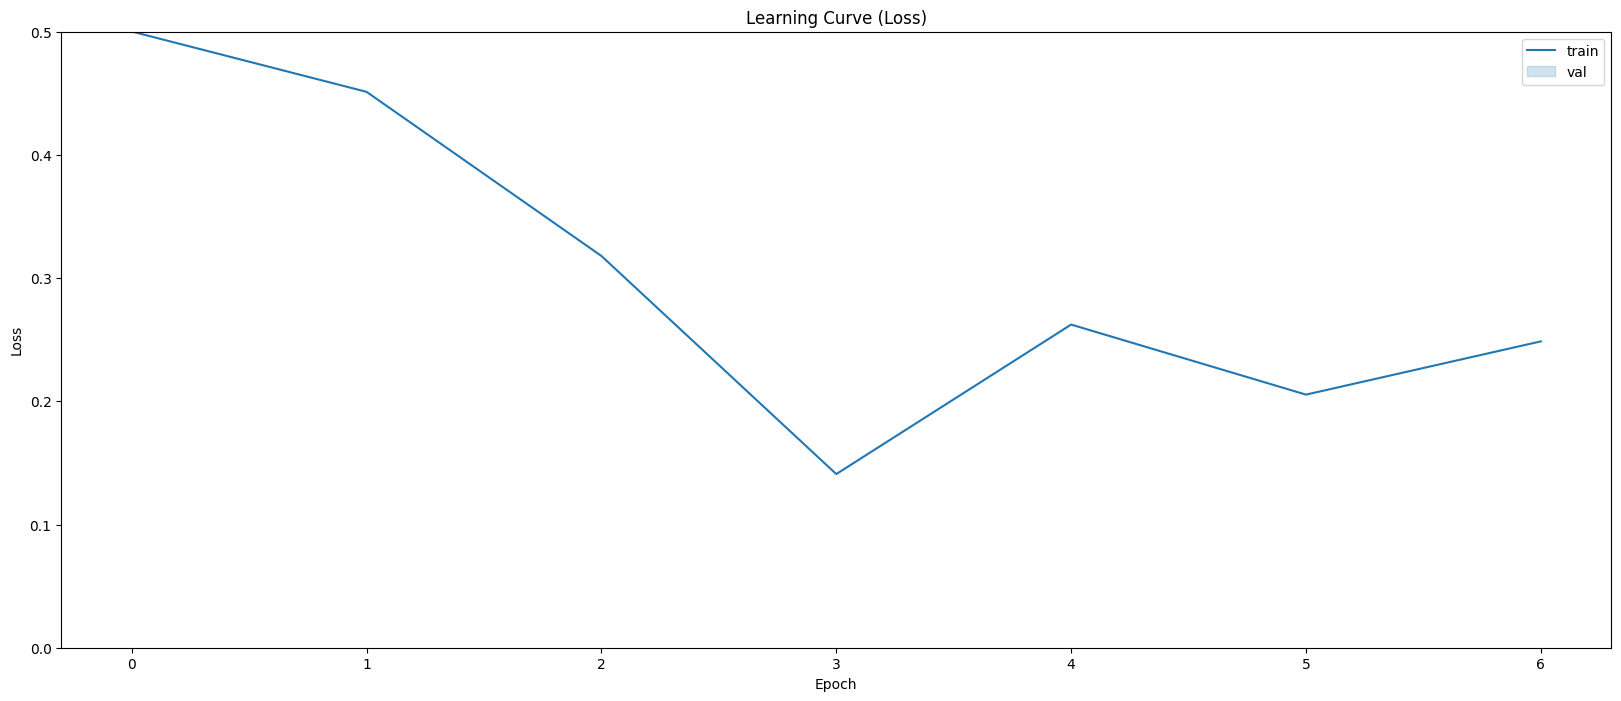

In [24]:
fig, ax = plt.subplots(figsize=(20,8))
sns.lineplot(x = history.epoch, y = history.history['loss'])
sns.lineplot(x = history.epoch, y = history.history['val_loss'])
ax.set_title('Learning Curve (Loss)')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.set_ylim(0, 0.5)
ax.legend(['train', 'val'], loc='best')
plt.show()

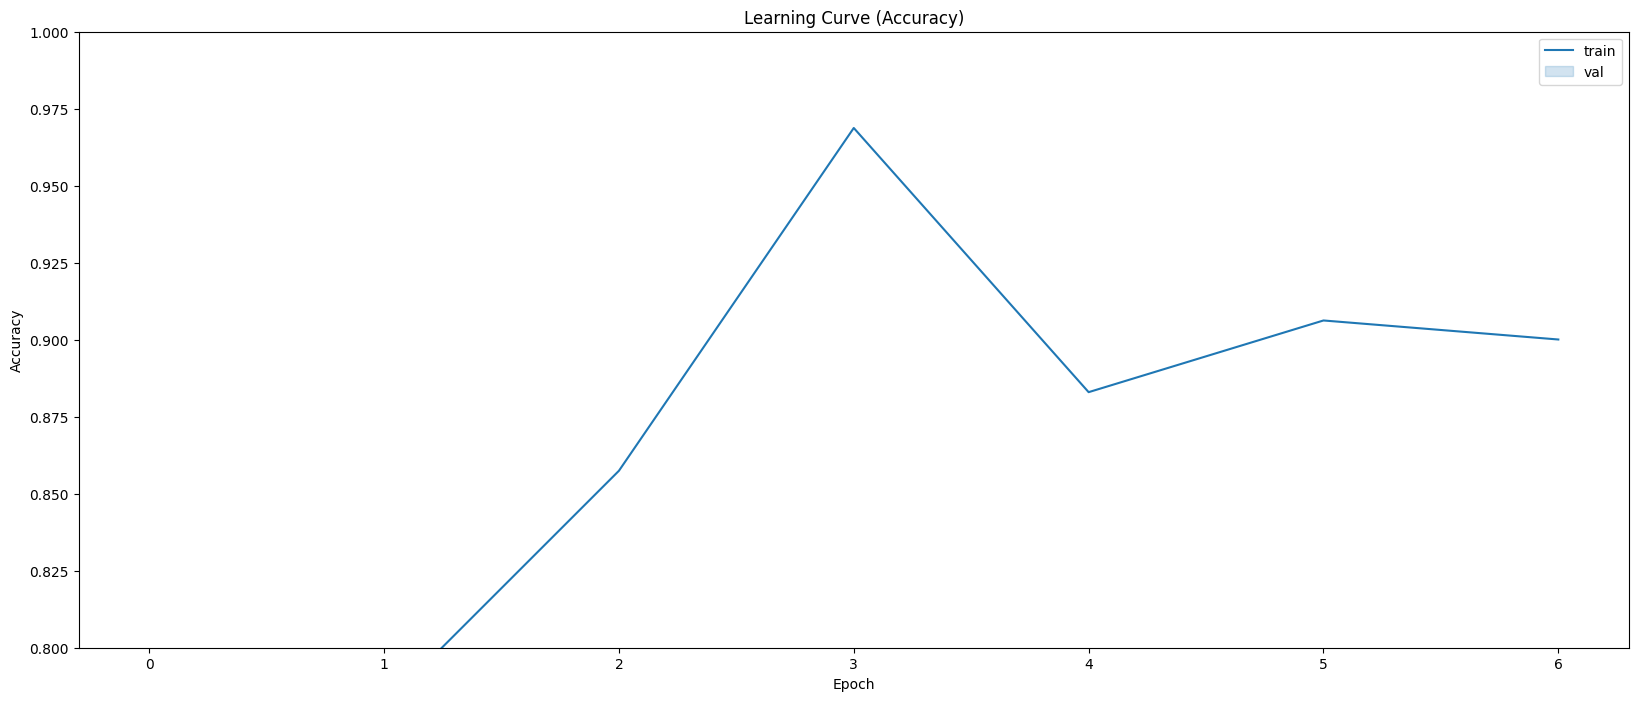

In [25]:
fig, ax = plt.subplots(figsize=(20,8))
sns.lineplot(x = history.epoch, y = history.history['binary_accuracy'])
sns.lineplot(x = history.epoch, y = history.history['val_binary_accuracy'])
ax.set_title('Learning Curve (Accuracy)')
ax.set_ylabel('Accuracy')
ax.set_xlabel('Epoch')
ax.set_ylim(0.80, 1.0)
ax.legend(['train', 'val'], loc='best')
plt.show()

In [26]:
score = model.evaluate(ds_val, steps = len(val_df)//BATCH, verbose = 0)
print('Val loss:', score[0])
print('Val accuracy:', score[1])

Val loss: 1.1257377862930298
Val accuracy: 0.7431640625


In [27]:
score = model.evaluate(ds_test, steps = len(df_test), verbose = 0)

print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 1.6442337036132812
Test accuracy: 0.625


# <a id="6">Transfer Learning</a>

The second approach, called transfer learning, consists of using a pretrained model as a feature extractor. In this notebook, the selected model was the ResNet152V2 available on the Keras Package [(link)](https://keras.io/api/applications/resnet/#resnet152v2-function).

This model was already trained in another dataset (ImageNet). What we do here is to set include_top to false, removing the ‘head’, responsible for assigning the classes in this other dataset, and keep all the previous layers. Then, we include our last few layers, including the one responsible for generating the output.



In [28]:
base_model = tf.keras.applications.ResNet152V2(
    weights='imagenet',
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False)

base_model.trainable = False

def get_pretrained():

    #Input shape = [width, height, color channels]
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    x = base_model(inputs)

    # Head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.1)(x)

    #Final Layer (Output)
    output = layers.Dense(1, activation='sigmoid')(x)

    model = keras.Model(inputs=[inputs], outputs=output)

    return model

234545216/234545216 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [29]:
keras.backend.clear_session()

model_pretrained = get_pretrained()
model_pretrained.compile(loss='binary_crossentropy'
              , optimizer = keras.optimizers.Adam(learning_rate=5e-5), metrics=['binary_accuracy'])

model_pretrained.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet152v2 (Functional)        │ (None, 7, 7, 2048)     │    58,331,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,594,049 (223.52 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 58,331,648 (222.52 MB)

In [30]:
history = model_pretrained.fit(ds_train,
          epochs = 50,
          validation_data=ds_val,
          callbacks=[early_stopping, plateau],
          steps_per_epoch=(len(train_df)//BATCH),
          validation_steps=(len(val_df)//BATCH));

Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 159s 1s/step - binary_accuracy: 0.8483 - loss: 0.3656 - val_binary_accuracy: 0.9277 - val_loss: 0.2122 - learning_rate: 5.0000e-05
Epoch 2/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 20s 141ms/step - binary_accuracy: 0.9062 - loss: 0.1882 - val_binary_accuracy: 0.9277 - val_loss: 0.2120 - learning_rate: 5.0000e-05
Epoch 3/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - binary_accuracy: 0.9232 - loss: 0.2053 - val_binary_accuracy: 0.9404 - val_loss: 0.1532 - learning_rate: 5.0000e-05
Epoch 4/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 19s 137ms/step - binary_accuracy: 0.9062 - loss: 0.3483 - val_binary_accuracy: 0.9404 - val_loss: 0.1536 - learning_rate: 5.0000e-05
Epoch 5/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - binary_accuracy: 0.9415 - loss: 0.1638 - val_binary_accuracy: 0.9541 - val_loss: 0.1321 - learning_rate: 5.0000e-05
Epoch 6/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 19s 140ms/step - binary_accuracy: 0.9688 - loss: 0.1433 - val_binary_accuracy: 0.9561 - val_loss: 0.1

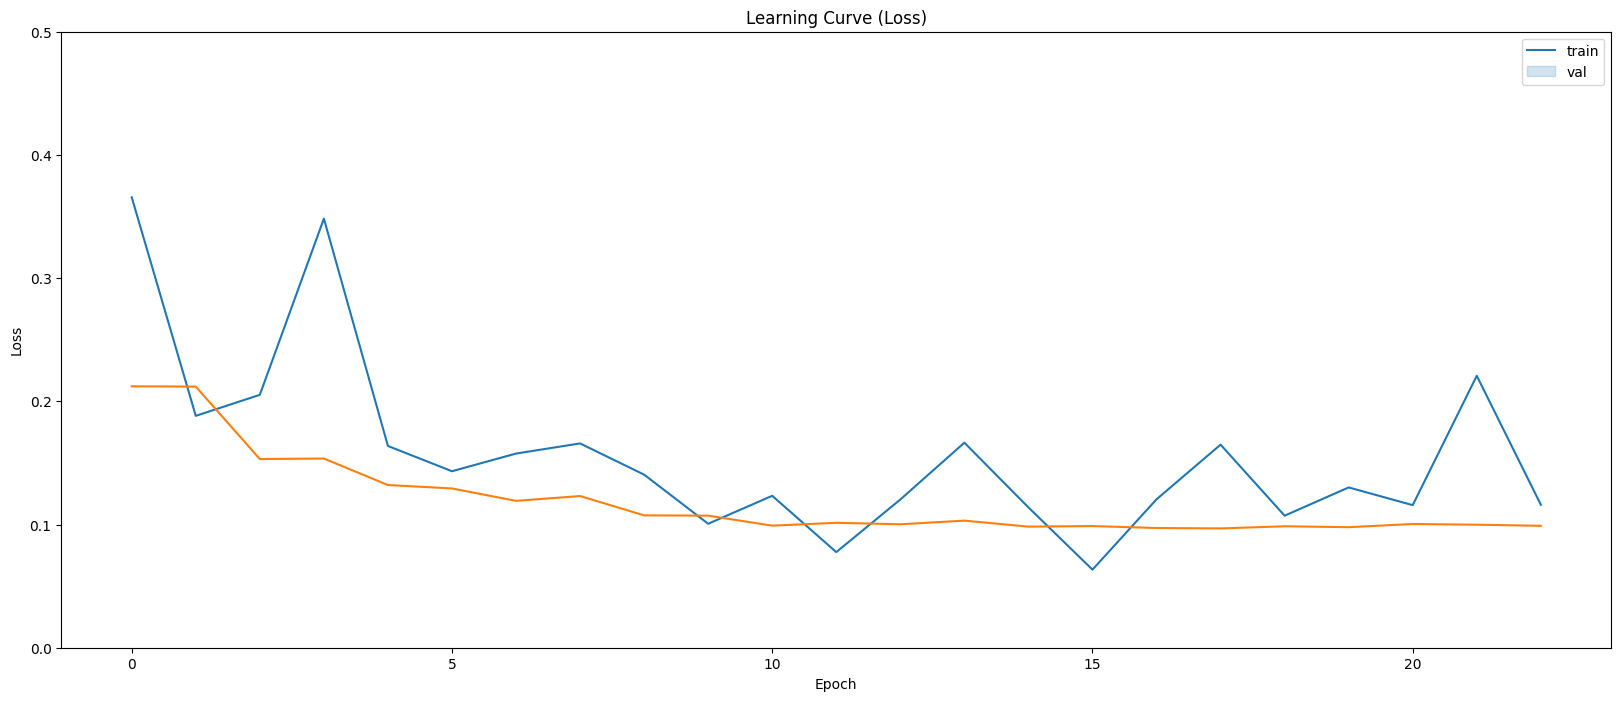

In [31]:
fig, ax = plt.subplots(figsize=(20,8))
sns.lineplot(x = history.epoch, y = history.history['loss'])
sns.lineplot(x = history.epoch, y = history.history['val_loss'])
ax.set_title('Learning Curve (Loss)')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.set_ylim(0, 0.5)
ax.legend(['train', 'val'], loc='best')
plt.show()

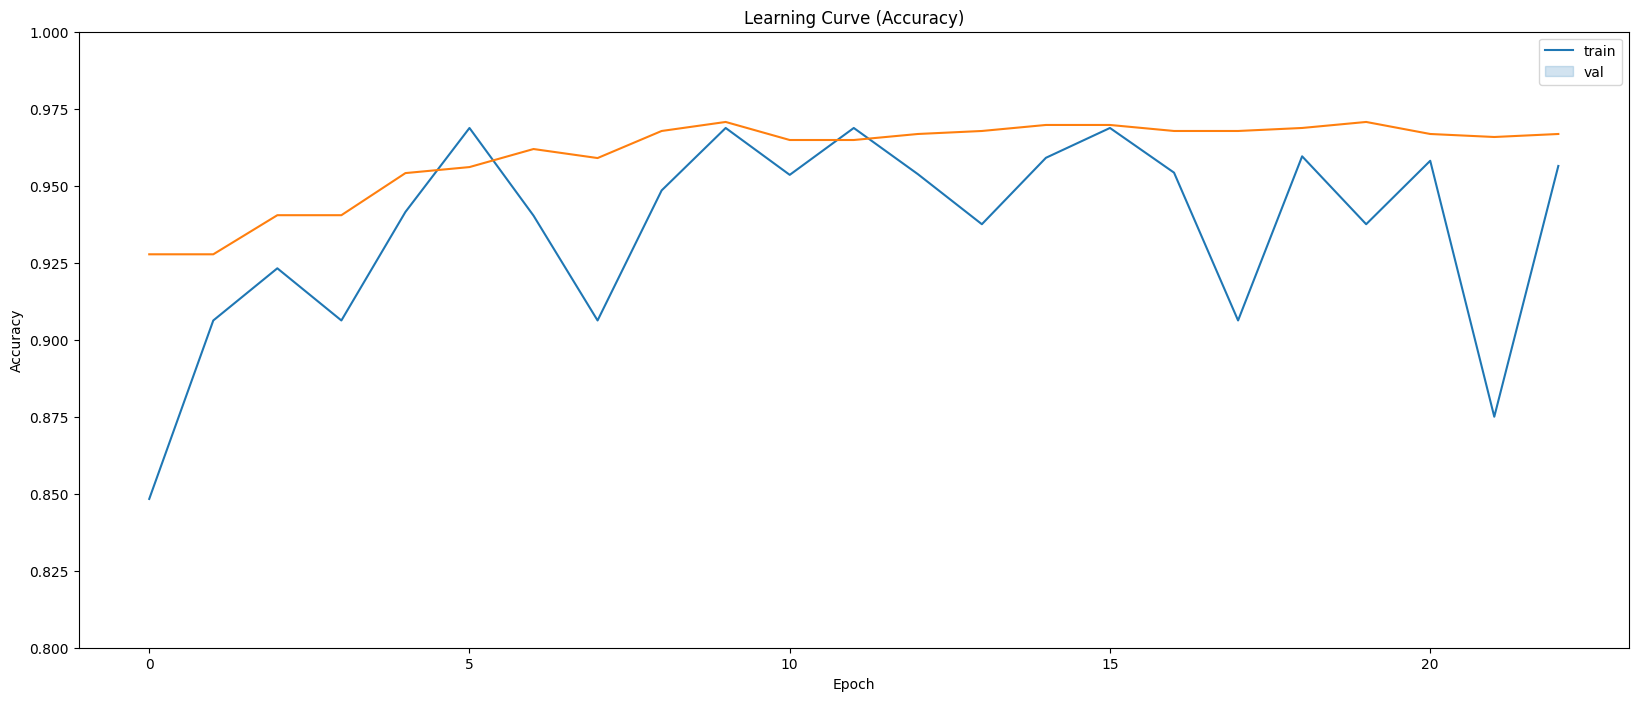

In [32]:
fig, ax = plt.subplots(figsize=(20,8))
sns.lineplot(x = history.epoch, y = history.history['binary_accuracy'])
sns.lineplot(x = history.epoch, y = history.history['val_binary_accuracy'])
ax.set_title('Learning Curve (Accuracy)')
ax.set_ylabel('Accuracy')
ax.set_xlabel('Epoch')
ax.set_ylim(0.80, 1.0)
ax.legend(['train', 'val'], loc='best')
plt.show()

In [33]:
score = model_pretrained.evaluate(ds_val, steps = len(val_df)//BATCH, verbose = 0)
print('Val loss:', score[0])
print('Val accuracy:', score[1])

Val loss: 0.09589508920907974
Val accuracy: 0.96875


In [34]:
score = model_pretrained.evaluate(ds_test, steps = len(df_test), verbose = 0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.29717910289764404
Test accuracy: 0.8814102411270142


# <a id="7">Fine Tuning</a>

Our last approach is called Fine Tuning. In the last section, all the layers from the pretrained model were ‘frozen’, preserving the weights calculated during its training on the ImageNet dataset. Now, we are going to unfreeze a few of its last layers and continue the training, tuning the weights from these layers according to our dataset.

In [35]:
base_model.trainable = True

# Freeze all layers except for the
for layer in base_model.layers[:-13]:
    layer.trainable = False

In [36]:
# Check which layers are tuneable (trainable)
for layer_number, layer in enumerate(base_model.layers):
    print(layer_number, layer.name, layer.trainable)

0 input_layer_1 False
1 conv1_pad False
2 conv1_conv False
3 pool1_pad False
4 pool1_pool False
5 conv2_block1_preact_bn False
6 conv2_block1_preact_relu False
7 conv2_block1_1_conv False
8 conv2_block1_1_bn False
9 conv2_block1_1_relu False
10 conv2_block1_2_pad False
11 conv2_block1_2_conv False
12 conv2_block1_2_bn False
13 conv2_block1_2_relu False
14 conv2_block1_0_conv False
15 conv2_block1_3_conv False
16 conv2_block1_out False
17 conv2_block2_preact_bn False
18 conv2_block2_preact_relu False
19 conv2_block2_1_conv False
20 conv2_block2_1_bn False
21 conv2_block2_1_relu False
22 conv2_block2_2_pad False
23 conv2_block2_2_conv False
24 conv2_block2_2_bn False
25 conv2_block2_2_relu False
26 conv2_block2_3_conv False
27 conv2_block2_out False
28 conv2_block3_preact_bn False
29 conv2_block3_preact_relu False
30 conv2_block3_1_conv False
31 conv2_block3_1_bn False
32 conv2_block3_1_relu False
33 conv2_block3_2_pad False
34 conv2_block3_2_conv False
35 conv2_block3_2_bn False
36 conv

In [37]:
model_pretrained.compile(loss='binary_crossentropy'
              , optimizer = keras.optimizers.Adam(learning_rate=2e-6), metrics=['binary_accuracy'])

model_pretrained.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet152v2 (Functional)        │ (None, 7, 7, 2048)     │    58,331,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,594,049 (223.52 MB)

 Trainable params: 4,731,137 (18.05 MB)

 Non-trainable params: 53,862,912 (205.47 MB)

In [38]:
history = model_pretrained.fit(ds_train,
          epochs = 50,
          validation_data=ds_val,
          callbacks=[early_stopping, plateau],
          steps_per_epoch=(len(train_df)//BATCH),
          validation_steps=(len(val_df)//BATCH));

Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 158s 1s/step - binary_accuracy: 0.9148 - loss: 0.2134 - val_binary_accuracy: 0.9521 - val_loss: 0.1664 - learning_rate: 2.0000e-06
Epoch 2/50
  1/130 ━━━━━━━━━━━━━━━━━━━━ 1:44 807ms/step - binary_accuracy: 1.0000 - loss: 0.0996
Epoch 2: ReduceLROnPlateau reducing learning rate to 3.999999989900971e-07.
130/130 ━━━━━━━━━━━━━━━━━━━━ 18s 136ms/step - binary_accuracy: 1.0000 - loss: 0.0996 - val_binary_accuracy: 0.9512 - val_loss: 0.1686 - learning_rate: 2.0000e-06
Epoch 3/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 132s 1s/step - binary_accuracy: 0.9441 - loss: 0.1748 - val_binary_accuracy: 0.9551 - val_loss: 0.1622 - learning_rate: 4.0000e-07
Epoch 4/50
  1/130 ━━━━━━━━━━━━━━━━━━━━ 1:49 847ms/step - binary_accuracy: 0.9062 - loss: 0.2229
Epoch 4: ReduceLROnPlateau reducing learning rate to 8.00000009348878e-08.
130/130 ━━━━━━━━━━━━━━━━━━━━ 19s 138ms/step - binary_accuracy: 0.9062 - loss: 0.2229 - val_binary_accuracy: 0.9541 - val_loss: 0.1658 - learning_rate: 

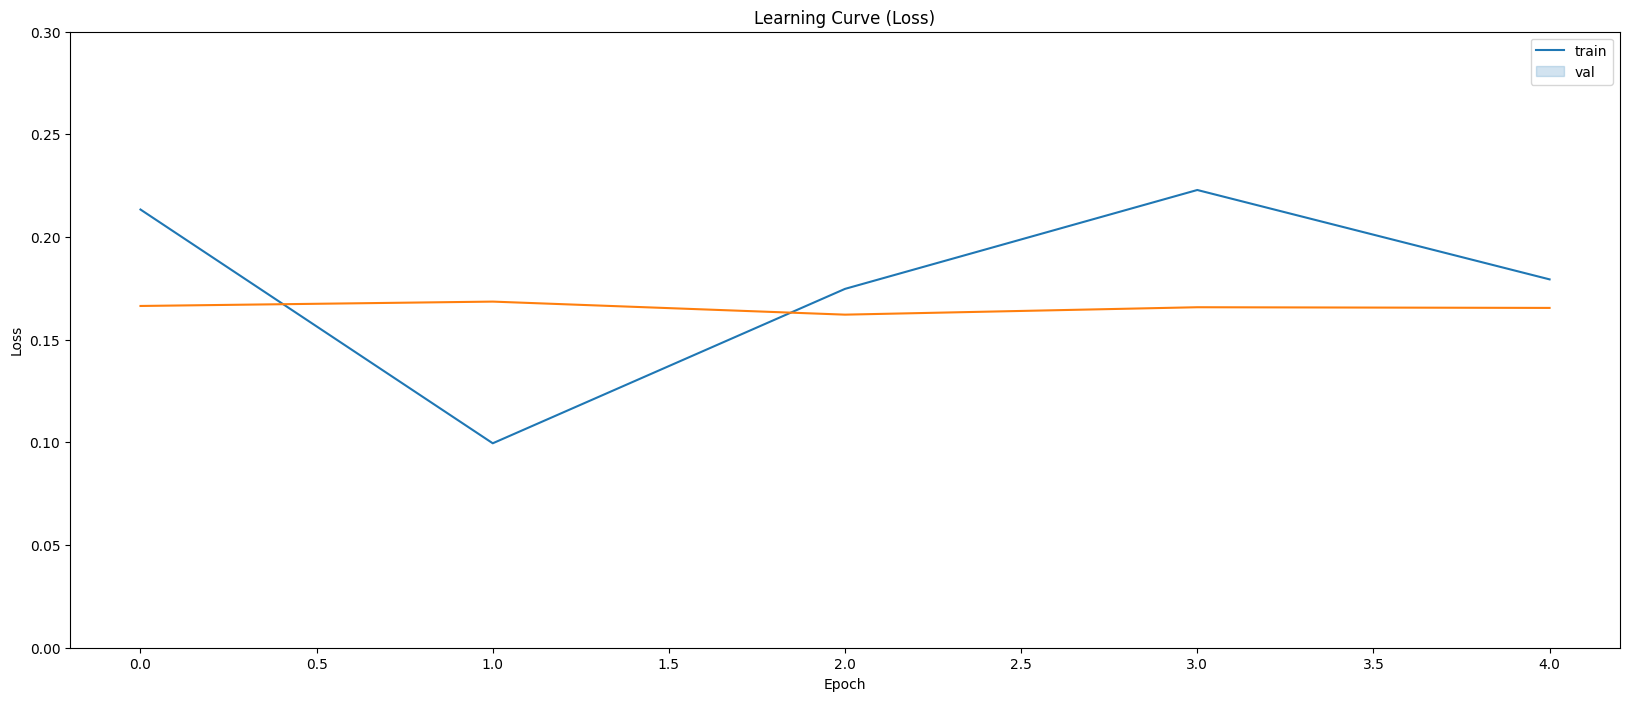

In [39]:
fig, ax = plt.subplots(figsize=(20,8))
sns.lineplot(x = history.epoch, y = history.history['loss'])
sns.lineplot(x = history.epoch, y = history.history['val_loss'])
ax.set_title('Learning Curve (Loss)')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.set_ylim(0, 0.3)
ax.legend(['train', 'val'], loc='best')
plt.show()

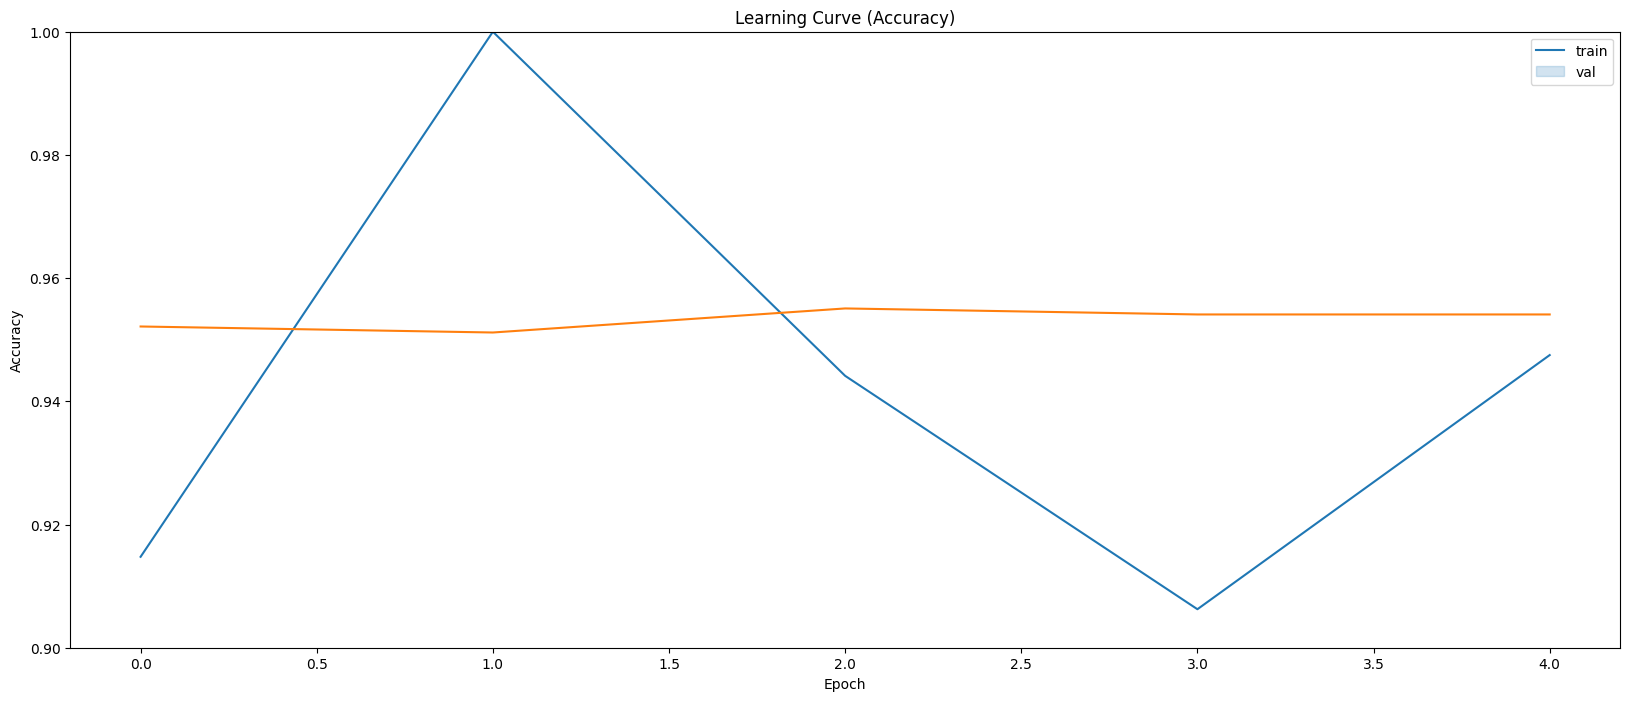

In [40]:
fig, ax = plt.subplots(figsize=(20,8))
sns.lineplot(x = history.epoch, y = history.history['binary_accuracy'])
sns.lineplot(x = history.epoch, y = history.history['val_binary_accuracy'])
ax.set_title('Learning Curve (Accuracy)')
ax.set_ylabel('Accuracy')
ax.set_xlabel('Epoch')
ax.set_ylim(0.90, 1.0)
ax.legend(['train', 'val'], loc='best')
plt.show()

In [41]:
score = model_pretrained.evaluate(ds_val, steps = len(val_df)//BATCH, verbose = 0)
print('Val loss:', score[0])
print('Val accuracy:', score[1])

Val loss: 0.16569286584854126
Val accuracy: 0.953125


In [42]:
score = model_pretrained.evaluate(ds_test, steps = len(df_test), verbose = 0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.23507514595985413
Test accuracy: 0.9150640964508057


As expected, the fine-tuning approach has reached the best score. We end this notebook by showing a few performance metrics.

# <a id="8">Performance Metrics</a>

In [43]:
num_label = {'Normal': 0, 'Pneumonia' : 1}
Y_test = df_test['class'].copy().map(num_label).astype('int')

In [44]:
ds_test.reset()
predictions = model_pretrained.predict(ds_test, steps=len(ds_test), verbose=0)
pred_labels= np.where(predictions>0.5, 1, 0)

In [45]:
print("Test Accuracy: ", accuracy_score(Y_test, pred_labels))

Test Accuracy:  0.9150641025641025


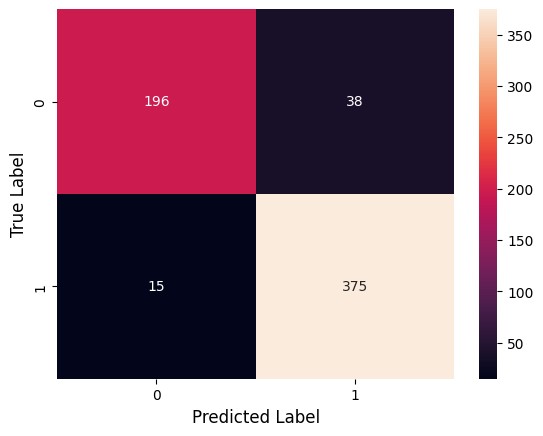

In [46]:
confusion_matrix = metrics.confusion_matrix(Y_test, pred_labels)
sns.heatmap(confusion_matrix, annot=True, fmt="d")

plt.xlabel("Predicted Label", fontsize= 12)
plt.ylabel("True Label", fontsize= 12)

plt.show()

In [47]:
print(metrics.classification_report(Y_test, pred_labels, labels = [0, 1]))

              precision    recall  f1-score   support

           0       0.93      0.84      0.88       234
           1       0.91      0.96      0.93       390

    accuracy                           0.92       624
   macro avg       0.92      0.90      0.91       624
weighted avg       0.92      0.92      0.91       624



ROC_AUC:  0.9674994521148368


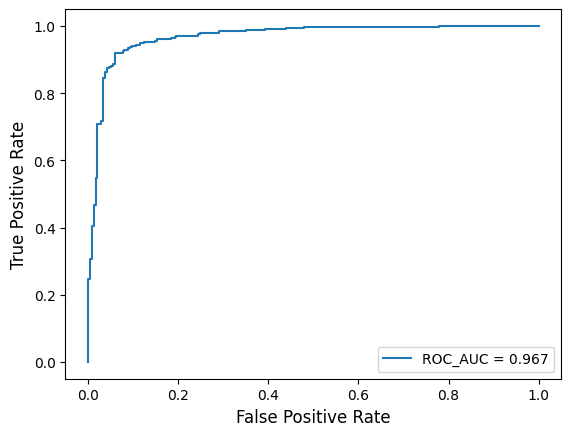

In [48]:
roc_auc = metrics.roc_auc_score(Y_test, predictions)
print('ROC_AUC: ', roc_auc)

fpr, tpr, thresholds = metrics.roc_curve(Y_test, predictions)

plt.plot(fpr, tpr, label = 'ROC_AUC = %0.3f' % roc_auc)

plt.xlabel("False Positive Rate", fontsize= 12)
plt.ylabel("True Positive Rate", fontsize= 12)
plt.legend(loc="lower right")

plt.show()

Pneumonia recall is 96% (375 of 390 pneumonia cases caught, 15 missed), with 91% precision and a ROC-AUC of 0.967. In a screening setting false negatives are usually costlier than false positives, so high recall matters. The trade-off is Normal recall of 84% (38 of 234 healthy X-rays flagged as pneumonia). Results come from a small, single-centre test set, so treat them as indicative rather than clinical evidence.

**My Custom Implementation: VGG-16 Transfer Learning:**

In [49]:
base_model_vgg = tf.keras.applications.VGG16(
    weights='imagenet',
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False)

# 2. FREEZE THE BASE LAYERS (Feature Extraction)
base_model_vgg.trainable = False

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [50]:
def get_vgg_model():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base_model_vgg(inputs)
    x = layers.GlobalAveragePooling2D()(x)

    # We are adding a slightly different Dropout here to experiment!
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)

    output = layers.Dense(1, activation='sigmoid')(x)
    model = keras.Model(inputs=[inputs], outputs=output)
    return model

keras.backend.clear_session()
my_vgg_model = get_vgg_model()

In [51]:
my_vgg_model.compile(loss='binary_crossentropy',
              optimizer = keras.optimizers.Adam(learning_rate=5e-5),
              metrics=['binary_accuracy'])

print("--- VGG-16 Model Built Successfully! ---")
my_vgg_model.summary()

--- VGG-16 Model Built Successfully! ---


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [52]:
print("\nStarting VGG-16 Training...")
history_vgg = my_vgg_model.fit(ds_train,
          epochs = 50,
          validation_data=ds_val,
          callbacks=[early_stopping, plateau],
          steps_per_epoch=(len(train_df)//BATCH),
          validation_steps=(len(val_df)//BATCH))



Starting VGG-16 Training...
Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 108s 820ms/step - binary_accuracy: 0.7291 - loss: 0.5766 - val_binary_accuracy: 0.7422 - val_loss: 0.5342 - learning_rate: 5.0000e-05
Epoch 2/50
  1/130 ━━━━━━━━━━━━━━━━━━━━ 1:19 617ms/step - binary_accuracy: 0.7812 - loss: 0.4966
Epoch 2: ReduceLROnPlateau reducing learning rate to 9.999999747378752e-06.
130/130 ━━━━━━━━━━━━━━━━━━━━ 14s 102ms/step - binary_accuracy: 0.7812 - loss: 0.4966 - val_binary_accuracy: 0.7393 - val_loss: 0.5363 - learning_rate: 5.0000e-05
Epoch 3/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - binary_accuracy: 0.7419 - loss: 0.5415 - val_binary_accuracy: 0.7412 - val_loss: 0.5262 - learning_rate: 1.0000e-05
Epoch 4/50
  1/130 ━━━━━━━━━━━━━━━━━━━━ 1:21 633ms/step - binary_accuracy: 0.7812 - loss: 0.5408
Epoch 4: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
130/130 ━━━━━━━━━━━━━━━━━━━━ 14s 101ms/step - binary_accuracy: 0.7812 - loss: 0.5408 - val_binary_accuracy: 0.7432 - 

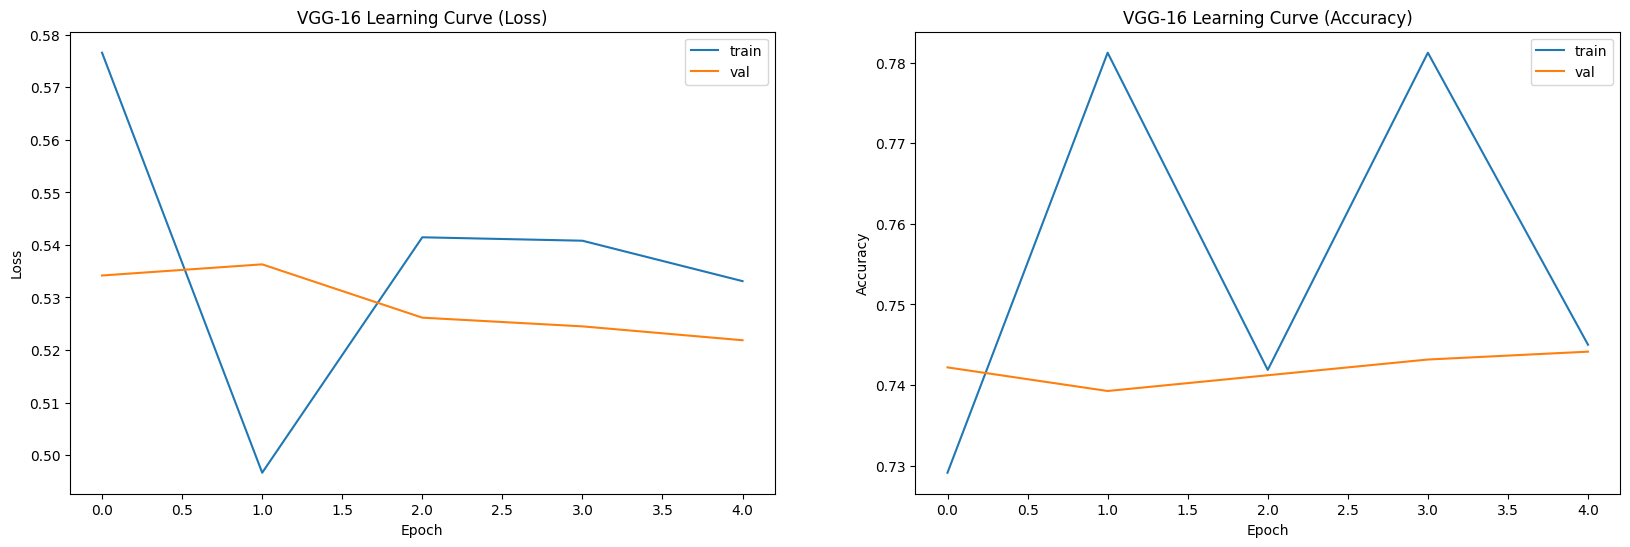

In [53]:
# 1. PLOT THE LEARNING CURVES FOR VGG-16
fig, ax = plt.subplots(1, 2, figsize=(20, 6))

# Loss Graph
sns.lineplot(x=history_vgg.epoch, y=history_vgg.history['loss'], ax=ax[0], label='train')
sns.lineplot(x=history_vgg.epoch, y=history_vgg.history['val_loss'], ax=ax[0], label='val')
ax[0].set_title('VGG-16 Learning Curve (Loss)')
ax[0].set_ylabel('Loss')
ax[0].set_xlabel('Epoch')

# Accuracy Graph
sns.lineplot(x=history_vgg.epoch, y=history_vgg.history['binary_accuracy'], ax=ax[1], label='train')
sns.lineplot(x=history_vgg.epoch, y=history_vgg.history['val_binary_accuracy'], ax=ax[1], label='val')
ax[1].set_title('VGG-16 Learning Curve (Accuracy)')
ax[1].set_ylabel('Accuracy')
ax[1].set_xlabel('Epoch')

plt.show()

In [54]:
print("\n--- VGG-16 FINAL SCORES ---")
# Validation Score
score_val = my_vgg_model.evaluate(ds_val, steps=len(val_df)//BATCH, verbose=0)
print(f'Val loss: {score_val[0]:.4f}')
print(f'Val accuracy: {score_val[1]:.4f}')

# Test Score (The one that matters!)
score_test = my_vgg_model.evaluate(ds_test, steps=len(df_test), verbose=0)
print(f'Test loss: {score_test[0]:.4f}')
print(f'Test accuracy: {score_test[1]:.4f}')


--- VGG-16 FINAL SCORES ---
Val loss: 0.5303
Val accuracy: 0.7461
Test loss: 0.6548
Test accuracy: 0.6250


**Fine Tuning the VGG-16 Model**

In [55]:
# 1. UNFREEZE THE BASE MODEL
base_model_vgg.trainable = True

# 2. FREEZE THE EARLY LAYERS (We will leave the top 4 layers unfrozen to learn)
for layer in base_model_vgg.layers[:-4]:
    layer.trainable = False


In [56]:

# Check which layers are trainable
for layer_number, layer in enumerate(base_model_vgg.layers):
    print(layer_number, layer.name, layer.trainable)


0 input_layer_1 False
1 block1_conv1 False
2 block1_conv2 False
3 block1_pool False
4 block2_conv1 False
5 block2_conv2 False
6 block2_pool False
7 block3_conv1 False
8 block3_conv2 False
9 block3_conv3 False
10 block3_pool False
11 block4_conv1 False
12 block4_conv2 False
13 block4_conv3 False
14 block4_pool False
15 block5_conv1 True
16 block5_conv2 True
17 block5_conv3 True
18 block5_pool True


In [57]:

# 3. RECOMPILE WITH A MICROSCOPIC LEARNING RATE
my_vgg_model.compile(loss='binary_crossentropy',
              optimizer = keras.optimizers.Adam(learning_rate=2e-6),
              metrics=['binary_accuracy'])

print("\n--- VGG-16 Ready for Fine-Tuning! ---")



--- VGG-16 Ready for Fine-Tuning! ---


In [58]:

# 4. TRAIN THE FINE-TUNED MODEL
history_vgg_fine = my_vgg_model.fit(ds_train,
          epochs = 50,
          validation_data=ds_val,
          callbacks=[early_stopping, plateau],
          steps_per_epoch=(len(train_df)//BATCH),
          validation_steps=(len(val_df)//BATCH))

Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 112s 840ms/step - binary_accuracy: 0.7650 - loss: 0.4663 - val_binary_accuracy: 0.8691 - val_loss: 0.3719 - learning_rate: 2.0000e-06
Epoch 2/50
  1/130 ━━━━━━━━━━━━━━━━━━━━ 1:22 638ms/step - binary_accuracy: 0.9688 - loss: 0.3035
Epoch 2: ReduceLROnPlateau reducing learning rate to 3.999999989900971e-07.
130/130 ━━━━━━━━━━━━━━━━━━━━ 20s 152ms/step - binary_accuracy: 0.9688 - loss: 0.3035 - val_binary_accuracy: 0.8770 - val_loss: 0.3682 - learning_rate: 2.0000e-06
Epoch 3/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 109s 838ms/step - binary_accuracy: 0.8420 - loss: 0.3510 - val_binary_accuracy: 0.8984 - val_loss: 0.3384 - learning_rate: 4.0000e-07
Epoch 4/50
  1/130 ━━━━━━━━━━━━━━━━━━━━ 1:26 669ms/step - binary_accuracy: 0.9375 - loss: 0.2183
Epoch 4: ReduceLROnPlateau reducing learning rate to 8.00000009348878e-08.
130/130 ━━━━━━━━━━━━━━━━━━━━ 14s 100ms/step - binary_accuracy: 0.9375 - loss: 0.2183 - val_binary_accuracy: 0.9004 - val_loss: 0.3357 - learning_

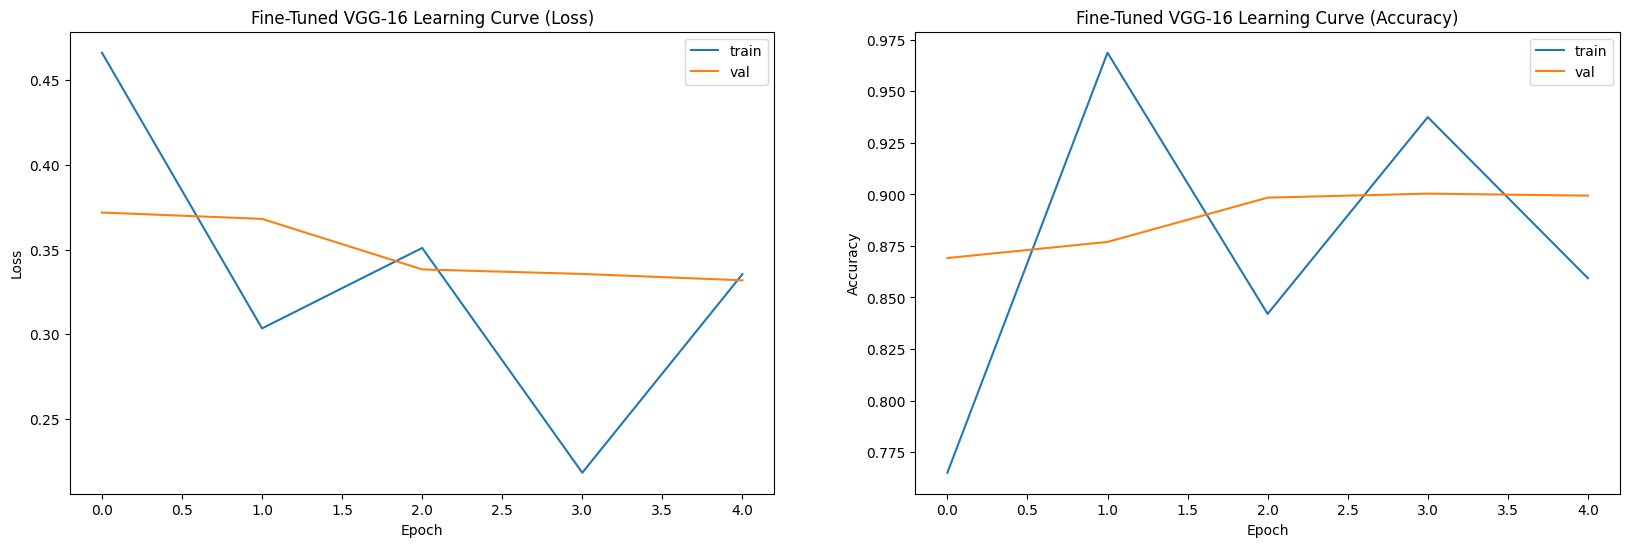

In [59]:
fig, ax = plt.subplots(1, 2, figsize=(20, 6))

# Loss Graph
sns.lineplot(x=history_vgg_fine.epoch, y=history_vgg_fine.history['loss'], ax=ax[0], label='train')
sns.lineplot(x=history_vgg_fine.epoch, y=history_vgg_fine.history['val_loss'], ax=ax[0], label='val')
ax[0].set_title('Fine-Tuned VGG-16 Learning Curve (Loss)')
ax[0].set_ylabel('Loss')
ax[0].set_xlabel('Epoch')

# Accuracy Graph
sns.lineplot(x=history_vgg_fine.epoch, y=history_vgg_fine.history['binary_accuracy'], ax=ax[1], label='train')
sns.lineplot(x=history_vgg_fine.epoch, y=history_vgg_fine.history['val_binary_accuracy'], ax=ax[1], label='val')
ax[1].set_title('Fine-Tuned VGG-16 Learning Curve (Accuracy)')
ax[1].set_ylabel('Accuracy')
ax[1].set_xlabel('Epoch')

plt.show()

In [60]:
print("\n--- VGG-16 FINE-TUNING FINAL SCORES ---")

# Validation Score
score_val_fine = my_vgg_model.evaluate(ds_val, steps=len(val_df)//BATCH, verbose=0)
print(f'Val loss: {score_val_fine[0]:.4f}')
print(f'Val accuracy: {score_val_fine[1]:.4f}')

# Test Score (The one that matters!)
score_test_fine = my_vgg_model.evaluate(ds_test, steps=len(df_test), verbose=0)
print(f'Test loss: {score_test_fine[0]:.4f}')
print(f'Test accuracy: {score_test_fine[1]:.4f}')


--- VGG-16 FINE-TUNING FINAL SCORES ---
Val loss: 0.3711
Val accuracy: 0.8682
Test loss: 0.4630
Test accuracy: 0.7756


# Project Conclusion: Architecture & Strategy Comparison

All numbers below are the actual outputs of the cells above (test set = 624 images).

| # | Model | Strategy | Val acc | Test acc |
|---|-------|----------|---------|----------|
| 1 | Custom CNN | From scratch | 74.3% | 62.5% |
| 2 | VGG-16 | Frozen base | 74.6% | 62.5% |
| 3 | VGG-16 | Fine-tuned (last 4 layers) | 86.8% | 77.6% |
| 4 | InceptionV3 | Frozen base | 94.4% | 86.5% |
| 5 | InceptionV3 | Fine-tuned (last 20 layers) | - | 87.0% |
| 6 | ResNet152V2 | Frozen base | 96.9% | 88.1% |
| 7 | **ResNet152V2** | **Fine-tuned (last 13 layers)** | 95.3% | **91.5%** |

## Key takeaways

1. **Models 1 and 2 did not learn.** 62.5% is exactly the share of Pneumonia images in the test set (390/624), and ~74% is the share in the validation set, so these models are effectively predicting "Pneumonia" for everything. This is a failure to learn rather than classic overfitting. For VGG-16 a likely contributor is that images were only rescaled by 1/255 instead of using VGG's own `preprocess_input`, combined with a very low learning rate and early stopping after ~5 epochs.
2. **Transfer learning helps a lot on this small dataset.** ResNet152V2 and InceptionV3 reach 86-88% with a frozen base, far above the from-scratch CNN.
3. **Fine-tuning gave the best result.** Unfreezing the last 13 ResNet152V2 layers at a learning rate of 2e-6 raised test accuracy from 88.1% to 91.5% and lowered test loss from 0.297 to 0.235, even though validation accuracy dipped slightly (96.9% to 95.3%).
4. **Best model (ResNet152V2 fine-tuned):** accuracy 91.5%, ROC-AUC 0.967, Pneumonia recall 0.96 / precision 0.91, Normal recall 0.84 / precision 0.93.

*Caveat:* the best model was chosen by comparing test scores across several candidates, so its test accuracy is slightly optimistic.

**Google Net **

In [27]:
# 1. IMPORT INCEPTION-V3
base_model_inception = tf.keras.applications.InceptionV3(
    weights='imagenet',
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False
)

# 2. FREEZE THE BASE LAYERS (Feature Extraction)
base_model_inception.trainable = False

# 3. BUILD THE CUSTOM HEAD
def get_inception_model():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # Pass the image through the frozen InceptionV3 body
    x = base_model_inception(inputs)
    x = layers.GlobalAveragePooling2D()(x)

    # Our custom brain
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)

    # Final Output (1 node, 0=Normal, 1=Pneumonia)
    output = layers.Dense(1, activation='sigmoid')(x)

    model = keras.Model(inputs=[inputs], outputs=output)
    return model

keras.backend.clear_session()
my_inception_model = get_inception_model()

# 4. COMPILE THE MODEL
my_inception_model.compile(loss='binary_crossentropy',
              optimizer = keras.optimizers.Adam(learning_rate=5e-5),
              metrics=['binary_accuracy'])

print("--- InceptionV3 Model Built Successfully! ---")

# 5. TRAIN THE FROZEN MODEL
print("\nStarting InceptionV3 Phase 1 Training...")
history_inception = my_inception_model.fit(ds_train,
          epochs = 50,
          validation_data=ds_val,
          callbacks=[early_stopping, plateau],
          steps_per_epoch=(len(train_df)//BATCH),
          validation_steps=(len(val_df)//BATCH))

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
--- InceptionV3 Model Built Successfully! ---

Starting InceptionV3 Phase 1 Training...
Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - binary_accuracy: 0.8353 - loss: 0.3691 - val_binary_accuracy: 0.9160 - val_loss: 0.2484 - learning_rate: 5.0000e-05
Epoch 2/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - binary_accuracy: 0.9688 - loss: 0.1290 - val_binary_accuracy: 0.9092 - val_loss: 0.2525 - learning_rate: 5.0000e-05
Epoch 3/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 105s 803ms/step - binary_accuracy: 0.9042 - loss: 0.2406 - val_binary_accuracy: 0.9307 - val_loss: 0.1987 - learning_rate: 5.0000e-05
Epoch 4/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 13s 96ms/step - binary_accuracy: 1.0000 - loss: 0.1266 - val_binary_accuracy: 0.9297 - val_loss: 0.1971 - learning_rate: 5.0000e-05
Epoch 5/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - binary_accuracy: 0.9109 - loss: 0.2139 - val_binary_accuracy: 0.9395 - val_loss: 0.1783 - learning_rate: 5.0000e-05
E

**SCore Measurement**

In [28]:
# EVALUATE PHASE 1: INCEPTION-V3 (FROZEN)
print("\n--- INCEPTION-V3 (FROZEN FEATURE EXTRACTOR) SCORES ---")

# Validation Score
score_val_inc_frozen = my_inception_model.evaluate(ds_val, steps=len(val_df)//BATCH, verbose=0)
print(f'Val loss: {score_val_inc_frozen[0]:.4f}')
print(f'Val accuracy: {score_val_inc_frozen[1]:.4f}')

# Test Score
score_test_inc_frozen = my_inception_model.evaluate(ds_test, steps=len(df_test), verbose=0)
print(f'Test loss: {score_test_inc_frozen[0]:.4f}')
print(f'Test accuracy: {score_test_inc_frozen[1]:.4f}')


--- INCEPTION-V3 (FROZEN FEATURE EXTRACTOR) SCORES ---
Val loss: 0.1572
Val accuracy: 0.9443
Test loss: 0.3181
Test accuracy: 0.8654


** Fine Tuning of the GoogleNet**

In [29]:
# 1. UNFREEZE THE BASE MODEL
base_model_inception.trainable = True

# 2. FREEZE THE EARLY LAYERS (Leaving only the top 20 unfrozen)
for layer in base_model_inception.layers[:-20]:
    layer.trainable = False

# 3. RECOMPILE WITH MICROSCOPIC LEARNING RATE (2e-6)
my_inception_model.compile(loss='binary_crossentropy',
              optimizer = keras.optimizers.Adam(learning_rate=2e-6),
              metrics=['binary_accuracy'])

print("\n--- InceptionV3 Ready for Fine-Tuning! ---")

# 4. TRAIN THE FINE-TUNED MODEL
history_inception_fine = my_inception_model.fit(ds_train,
          epochs = 15,
          validation_data=ds_val,
          callbacks=[early_stopping, plateau],
          steps_per_epoch=(len(train_df)//BATCH),
          validation_steps=(len(val_df)//BATCH))


--- InceptionV3 Ready for Fine-Tuning! ---
Epoch 1/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 134s 956ms/step - binary_accuracy: 0.9307 - loss: 0.1986 - val_binary_accuracy: 0.9385 - val_loss: 0.1769 - learning_rate: 2.0000e-06
Epoch 2/15
  1/130 ━━━━━━━━━━━━━━━━━━━━ 1:41 787ms/step - binary_accuracy: 0.9062 - loss: 0.2456
Epoch 2: ReduceLROnPlateau reducing learning rate to 3.999999989900971e-07.
130/130 ━━━━━━━━━━━━━━━━━━━━ 14s 105ms/step - binary_accuracy: 0.9062 - loss: 0.2456 - val_binary_accuracy: 0.9404 - val_loss: 0.1760 - learning_rate: 2.0000e-06
Epoch 3/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 112s 863ms/step - binary_accuracy: 0.9326 - loss: 0.1927 - val_binary_accuracy: 0.9414 - val_loss: 0.1791 - learning_rate: 4.0000e-07
Epoch 4/15
  1/130 ━━━━━━━━━━━━━━━━━━━━ 1:25 664ms/step - binary_accuracy: 0.9062 - loss: 0.2296
Epoch 4: ReduceLROnPlateau reducing learning rate to 8.00000009348878e-08.
130/130 ━━━━━━━━━━━━━━━━━━━━ 14s 104ms/step - binary_accuracy: 0.9062 - loss: 0.2296 - val_binary_acc

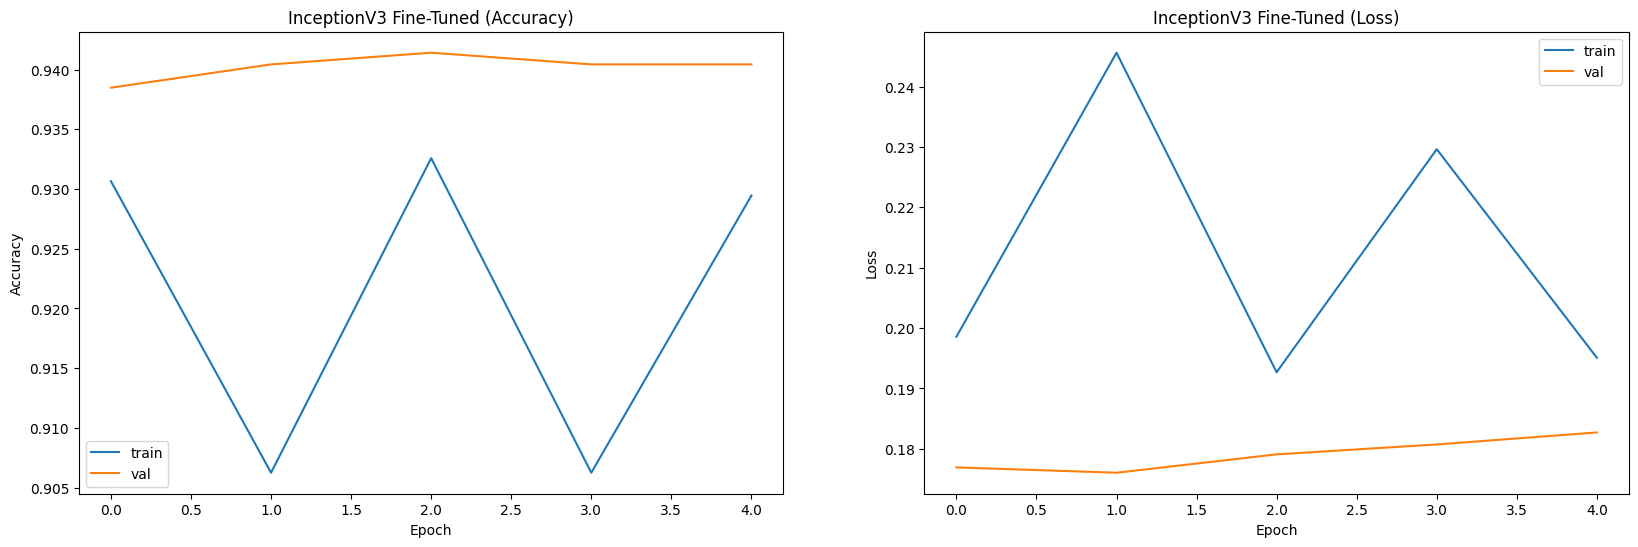


--- INCEPTION-V3 FINAL SCORES ---
Test loss: 0.3085
Test accuracy: 0.8702


In [30]:
# 1. PLOT THE LEARNING CURVES
fig, ax = plt.subplots(1, 2, figsize=(20, 6))

# Accuracy Graph
sns.lineplot(x=history_inception_fine.epoch, y=history_inception_fine.history['binary_accuracy'], ax=ax[0], label='train')
sns.lineplot(x=history_inception_fine.epoch, y=history_inception_fine.history['val_binary_accuracy'], ax=ax[0], label='val')
ax[0].set_title('InceptionV3 Fine-Tuned (Accuracy)')
ax[0].set_ylabel('Accuracy')
ax[0].set_xlabel('Epoch')

# Loss Graph
sns.lineplot(x=history_inception_fine.epoch, y=history_inception_fine.history['loss'], ax=ax[1], label='train')
sns.lineplot(x=history_inception_fine.epoch, y=history_inception_fine.history['val_loss'], ax=ax[1], label='val')
ax[1].set_title('InceptionV3 Fine-Tuned (Loss)')
ax[1].set_ylabel('Loss')
ax[1].set_xlabel('Epoch')

plt.show()

# 2. THE FINAL EXAM
print("\n--- INCEPTION-V3 FINAL SCORES ---")
score_test_inc = my_inception_model.evaluate(ds_test, steps=len(df_test), verbose=0)
print(f'Test loss: {score_test_inc[0]:.4f}')
print(f'Test accuracy: {score_test_inc[1]:.4f}')

In [1]:
import numpy as np
import cv2
from google.colab import files
import matplotlib.pyplot as plt

print("=== PNEUMONIA AI DIAGNOSTIC TOOL ===")
print("Please upload a Chest X-Ray image (.jpg, .jpeg, or .png)")

uploaded = files.upload()

for fn in uploaded.keys():
  path = '/content/' + fn
  img_original = cv2.imread(path)

  img_rgb = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB)

  img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
  img_scaled = img_resized / 255.0
  img_ready = np.expand_dims(img_scaled, axis=0)

  prediction = model_pretrained.predict(img_ready, verbose=0)

  probability = prediction[0][0]

  plt.figure(figsize=(5,5))
  plt.imshow(img_rgb)
  plt.axis('off')

  if probability > 0.5:
      plt.title(f"Diagnosis: PNEUMONIA \n(Confidence: {probability*100:.2f}%)", color='red', fontsize=14, fontweight='bold')
  else:
      plt.title(f"Diagnosis: NORMAL \n(Confidence: {(1-probability)*100:.2f}%)", color='green', fontsize=14, fontweight='bold')

  plt.show()

=== PNEUMONIA AI DIAGNOSTIC TOOL ===
Please upload a Chest X-Ray image (.jpg, .jpeg, or .png)


KeyboardInterrupt: 

# <a id="9">References</a>

- https://vijayabhaskar96.medium.com/tutorial-on-keras-flow-from-dataframe-1fd4493d237c
- https://github.com/mrdbourke/tensorflow-deep-learning/blob/main/03_convolutional_neural_networks_in_tensorflow.ipynb
- https://www.tensorflow.org/guide/keras/transfer_learning
- https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator
- https://keras.io/api/applications/
- https://keras.io/api/applications/resnet/#resnet152v2-function

## <center> If you find this notebook useful, support with an upvote! <center>